In [27]:
# 구글 드라이브 마운트

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# 데이터 준비 및 전처리

### 필요한 데이터 다운 받기

**Histological tile 이미지 (5000장, 150x150 픽셀 (74x74 µm))**

```
Kather_texture_2016_image_tiles_5000
|--01_TUMOR
|    |--10009_CRC-Prim-HE-03_009.tif_Row_301_Col_151.tif
|    |--10062_CRC-Prim-HE-02_003b.tif_Row_1_Col_301.tif
|    |--100B0_CRC-Prim-HE-09_009.tif_Row_1_Col_301.tif
|     ...
|--02_STROMA
|    |--10009_CRC-Prim-HE-03_009.tif_Row_301_Col_151.tif
|    |--1000E_CRC-Prim-HE-04.tif_Row_1501_Col_451.tif
|    |--10049_CRC-Prim-HE-07_014.tif_Row_601_Col_3001.tif
|    ...


```

In [7]:
# 5000 150 * 150 histological 이미지 (74 * 74 µm)
!wget -O histology_dataset.zip --no-check-certificate https://zenodo.org/records/53169/files/Kather_texture_2016_image_tiles_5000.zip?download=1

!unzip histology_dataset.zip # 압축 풀기

스트리밍 출력 내용이 길어서 마지막 5000줄이 삭제되었습니다.
  inflating: Kather_texture_2016_image_tiles_5000/01_TUMOR/10264_CRC-Prim-HE-07_025.tif_Row_1801_Col_1.tif  
  inflating: Kather_texture_2016_image_tiles_5000/01_TUMOR/10286_CRC-Prim-HE-01_002.tif_Row_301_Col_1.tif  
  inflating: Kather_texture_2016_image_tiles_5000/01_TUMOR/1030D_CRC-Prim-HE-02_031.tif_Row_151_Col_1.tif  
  inflating: Kather_texture_2016_image_tiles_5000/01_TUMOR/103B7_CRC-Prim-HE-02_026.tif_Row_1_Col_451.tif  
  inflating: Kather_texture_2016_image_tiles_5000/01_TUMOR/103F_CRC-Prim-HE-02_025.tif_Row_1_Col_301.tif  
  inflating: Kather_texture_2016_image_tiles_5000/01_TUMOR/103F_CRC-Prim-HE-10_013.tif_Row_151_Col_1.tif  
  inflating: Kather_texture_2016_image_tiles_5000/01_TUMOR/10437_CRC-Prim-HE-02_028.tif_Row_151_Col_451.tif  
  inflating: Kather_texture_2016_image_tiles_5000/01_TUMOR/104D5_CRC-Prim-HE-09_024.tif_Row_451_Col_151.tif  
  inflating: Kather_texture_2016_image_tiles_5000/01_TUMOR/1055E_CRC-Prim-HE-01_027.tif_Row_151_C

[1000000_colon_histological_images](https://zenodo.org/record/1214456/#.YsjR3OxBw0Q)

### 다운 받은 데이터 확인

In [2]:
import os

In [3]:
def print_files_in_dir(root_dir, prefix):
    files = os.listdir(root_dir)
    for file in files:
        path = os.path.join(root_dir, file)
        file_list = os.listdir(path)
        print(f"{prefix + path} 폴더의 데이터 수: {len(file_list)}")
        # print(f"해당 폴더의 데이터의 수 {len(file_list)}")

In [8]:
print_files_in_dir("Kather_texture_2016_image_tiles_5000", "")

Kather_texture_2016_image_tiles_5000/04_LYMPHO 폴더의 데이터 수: 625
Kather_texture_2016_image_tiles_5000/08_EMPTY 폴더의 데이터 수: 625
Kather_texture_2016_image_tiles_5000/03_COMPLEX 폴더의 데이터 수: 625
Kather_texture_2016_image_tiles_5000/01_TUMOR 폴더의 데이터 수: 625
Kather_texture_2016_image_tiles_5000/02_STROMA 폴더의 데이터 수: 625
Kather_texture_2016_image_tiles_5000/07_ADIPOSE 폴더의 데이터 수: 625
Kather_texture_2016_image_tiles_5000/05_DEBRIS 폴더의 데이터 수: 625
Kather_texture_2016_image_tiles_5000/06_MUCOSA 폴더의 데이터 수: 625


### 학습, 검증 데이터 준비

In [8]:
def create_dir(dir_name : str):
  """
  디렉토리가 존재하지 않으면 생성
  """
  if not os.path.exists(dir_name):
      os.makedirs(dir_name)

In [9]:
image_file_root      = "Kather_texture_2016_image_tiles_5000"
train_dataset_folder = "training_dataset" # 학습 데이터 저장할 폴더
val_dataset_folder   = "validation_dataset" # 검증 데이터 저장할 폴더

In [10]:
files = os.listdir(image_file_root)

In [11]:
files.sort() # 클래스 번호로 정렬하기
files

['01_TUMOR',
 '02_STROMA',
 '03_COMPLEX',
 '04_LYMPHO',
 '05_DEBRIS',
 '06_MUCOSA',
 '07_ADIPOSE',
 '08_EMPTY']



![](https://media.springernature.com/full/springer-static/image/art%3A10.1038%2Fsrep27988/MediaObjects/41598_2016_Article_BFsrep27988_Fig1_HTML.jpg?as=webp)



1. **TUM:** 대장 선암 상피 (Colorectal adenocarcinoma epithelium) - 암세포
2. **STR:** 암 연관 기질 (Cancer-associated stroma)
3. **LYM:** 림프구 (Lymphocytes) - 면역 세포 군집
4. **MUC:** 점액 (Mucus)
5. **NORM:** 정상 대장 점막 (Normal colon mucosa)
6. **MUS:** 평활근 (Smooth muscle)
7. **ADI:** 지방 조직 (Adipose tissue)
8. **DEB:** 파편 (Debris) - 괴사 등
9. **BACK:** 배경 (Background) - 조직이 없는 빈 공간

In [12]:
create_dir(train_dataset_folder) # 학습 데이터 저장할 폴더 생성
create_dir(val_dataset_folder) # 검증 데이터 저장할 폴더 생성

# 클래스별 서브 디렉토리 생성
for class_name in files:
  train_sub_folder_path = os.path.join(train_dataset_folder, class_name)
  create_dir(train_sub_folder_path)
  val_sub_folder_path = os.path.join(val_dataset_folder, class_name)
  create_dir(val_sub_folder_path)


In [13]:
import random
from shutil import copyfile

In [14]:
# 전체 데이터에서 학습 / 검증 데이터 나누기

for class_name in files:
  image_files = os.listdir(os.path.join(image_file_root, class_name)) # 전체 이미지
  random.shuffle(image_files) # 이미지 랜덤하게 섞기

  train_image_list = image_files[:500] # 학습데이터 (500장)
  val_image_list = image_files[500:] # 검증데이터 (나머지)

  # 학습데이터 폴더와 검증데이터 폴더에 나누어 저장하기
  for train_image in train_image_list:
    copyfile(os.path.join(image_file_root, class_name, train_image), os.path.join(train_dataset_folder, class_name, train_image))
  for val_image in val_image_list:
    copyfile(os.path.join(image_file_root, class_name, val_image), os.path.join(val_dataset_folder, class_name, val_image))


### 데이터 전처리

In [15]:
# 필요한 모듈 불러오기

import torch
from torchvision import datasets, models, transforms
from torchvision.models import resnet50
from torch.utils.tensorboard import SummaryWriter
import torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler
# from nets import *
import time, os, copy, argparse
import multiprocessing
from torchsummary import summary
from matplotlib import pyplot as plt

import cv2
import numpy as np

import torch.utils.data as data

In [16]:
# 데이터 transform 적용하기

image_transforms = {
    'train': transforms.Compose([
        transforms.Resize(size=224), # 패치 사이즈 224로 만들기
        transforms.ToTensor(),       # 텐서로 변환

        # 데이터 augmentaion
        transforms.RandomRotation(90, expand=False),  # 90도 회전
        transforms.RandomRotation(180, expand=False), # 180도 회전
        transforms.RandomRotation(270, expand=False), # 270도 회전

        # 이미지 정규화 (각 채널의 평균, 표준편차 값)
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),

    'valid': transforms.Compose([
        transforms.Resize(size=224),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ])
}

In [ ]:
# train_directory = './training_dataset' # training 데이터 경로
# valid_directory = './validation_dataset' # validation 데이터 경로
# PATH            = "model.pth" # 사전에 저장된 모델 경로

In [17]:
bs = 32 # 미니 배치(mini-batch) 학습을 위한 Batch size

# 경로에서 데이터 불러오기
dataset = {
    'train': datasets.ImageFolder(root=train_dataset_folder, transform=image_transforms['train']),
    'valid': datasets.ImageFolder(root=val_dataset_folder, transform=image_transforms['valid'])
}

# 각 데이터 크기 저장
dataset_sizes = {
    'train':len(dataset['train']),
    'valid':len(dataset['valid'])
}

# mini-batch 학습을 위한 iterators 객체 만들기
dataloaders = {
    'train':data.DataLoader(dataset['train'], batch_size=bs, shuffle=True,
                            num_workers=1, pin_memory=True, drop_last=False),
    'valid':data.DataLoader(dataset['valid'], batch_size=bs, shuffle=False,
                            num_workers=1, pin_memory=True, drop_last=False)
}


# 클래스 이름 출력
class_names = dataset['train'].classes
print("Classes:", class_names)


# 학습 / 검증 데이터 사이즈 출력
print("Training-set size:",dataset_sizes['train'],
      "\nValidation-set size:", dataset_sizes['valid'])

Classes: ['01_TUMOR', '02_STROMA', '03_COMPLEX', '04_LYMPHO', '05_DEBRIS', '06_MUCOSA', '07_ADIPOSE', '08_EMPTY']
Training-set size: 4000 
Validation-set size: 1000


In [18]:
# Train DataLoader 데이터 확인해보기

for x, y in dataloaders['train']:
    print(x.shape)
    print(y.shape)
    break

torch.Size([32, 3, 224, 224])
torch.Size([32])


In [20]:
# Valid DataLoader 데이터 확인해보기

for x, y in dataloaders['valid']:
    print(x.shape)
    print(y.shape)
    break

torch.Size([32, 3, 224, 224])
torch.Size([32])


# 모델 학습 (Model training)

### 모델 학습을 위한 설정

In [19]:
# 학습에 필요한 변수 설정

train_epoch   = 10 # Number of epochs
learning_rate = 0.005 # Learning rate for optimizer

In [20]:
# 디바이스 설정 (GPU 사용 가능하면 GPU 사용하도록)
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

# ImageNet 데이터로 사전학습된 resnet50 모델 불러오기
model = resnet50(pretrained=True)

# resnet50의 마지막 층 교체
# (2048 -> 1000) => (2048 -> 128 -> num_classes)
model.fc = nn.Sequential(
              nn.Linear(2048, 128),
              nn.ReLU(inplace=True),
              nn.Linear(128, 8))


# 모델 GPU 메모리에 올리기
model = model.to(device)

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 197MB/s]


In [21]:
model

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [22]:
# 손실 함수 정의하기
loss_fn = nn.CrossEntropyLoss()

# Optimizer (Stochastic Gradient Descent)
opt = optim.SGD(model.parameters(), lr=learning_rate, momentum=0.9)

# Learning rate decay
scheduler = lr_scheduler.StepLR(opt, step_size=7, gamma=0.1)

### 모델 학습 진행

In [23]:
import time
import copy

In [24]:
def train_model(model, criterion, optimizer, scheduler, num_epochs=30):
    """모델 학습을 위한 함수

    args:
      model: 사전엔 생성된 모델 인스턴스
      criterion: 모델 학습 및 평가에 활용 되는 손실 함수
      optimzer: gradient 값을 바탕으로 매개변수를 업데이트
      scheduler: 학습 과정 동안 학습률(learning rate) 조정
      num_epochs: 학습 시 최대 epoch 수 (default: 30)

    return:
      학습된 모델 반환
    """
    since = time.time() # 학습 시작 시간 기록

    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0


    for epoch in range(num_epochs):
        print('Epoch {}/{}'.format(epoch, num_epochs - 1))
        print('-' * 10)

        # 각 epoch 마다 학습과 검증 수행
        for phase in ['train', 'valid']:
            if phase == 'train':
                model.train()  # training 모드로 전환
            else:
                model.eval()   # evalutation 모드로 전환

            running_loss = 0.0
            running_corrects = 0

            # 미니 배치(mini-batch) 학습
            for inputs, labels in dataloaders[phase]:
                inputs = inputs.to(device)
                labels = labels.to(device)

                # gradient를 0으로 초기화
                optimizer.zero_grad()

                # 순전파(forward)
                # 학습 과정에서만 연산 기록 추적
                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)

                    # 학습 과정에서만
                    if phase == 'train':
                        loss.backward() # 오차 역전파(backward)
                        optimizer.step() # 매개변수 업데이트

                # 손실 값(loss)과 정확도(accuracy) 계산을 위한 통계랑 저장
                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)
            if phase == 'train':
                scheduler.step()

            # 평균 손실 값과 정확도
            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = running_corrects.double() / dataset_sizes[phase]

            print('{} Loss: {:.4f} Acc: {:.4f}'.format(phase, epoch_loss, epoch_acc))

            # 검증 정확도가 가장 높은 모델 저장하기
            if phase == 'valid' and epoch_acc > best_acc:
                best_acc = epoch_acc
                best_model_wts = copy.deepcopy(model.state_dict())

        print()

    time_elapsed = time.time() - since # 학습 종료 시간 기록
    print('Training complete in {:.0f}m {:.0f}s'.format(time_elapsed // 60, time_elapsed % 60))
    print('Best val Acc: {:4f}'.format(best_acc))

    # 검증 시 정확도가 제일 높은 모델 불러오기
    model.load_state_dict(best_model_wts)
    return model

In [27]:
# Model training routine
print("\nTraining:-\n")

model = train_model(model, loss_fn, opt, scheduler, num_epochs=train_epoch)


Training:-

Epoch 0/9
----------
train Loss: 0.7744 Acc: 0.7460
valid Loss: 0.2968 Acc: 0.9020

Epoch 1/9
----------
train Loss: 0.3251 Acc: 0.8890
valid Loss: 0.3193 Acc: 0.8780

Epoch 2/9
----------
train Loss: 0.2526 Acc: 0.9173
valid Loss: 0.1539 Acc: 0.9430

Epoch 3/9
----------
train Loss: 0.2108 Acc: 0.9303
valid Loss: 0.3035 Acc: 0.8960

Epoch 4/9
----------
train Loss: 0.2027 Acc: 0.9285
valid Loss: 0.2218 Acc: 0.9210

Epoch 5/9
----------
train Loss: 0.1752 Acc: 0.9383
valid Loss: 0.2209 Acc: 0.9350

Epoch 6/9
----------
train Loss: 0.1711 Acc: 0.9437
valid Loss: 0.2495 Acc: 0.9270

Epoch 7/9
----------
train Loss: 0.1086 Acc: 0.9617
valid Loss: 0.1150 Acc: 0.9600

Epoch 8/9
----------
train Loss: 0.1021 Acc: 0.9663
valid Loss: 0.1070 Acc: 0.9650

Epoch 9/9
----------
train Loss: 0.0904 Acc: 0.9673
valid Loss: 0.1043 Acc: 0.9670

Training complete in 10m 56s
Best val Acc: 0.967000


# 모델 테스트 (Model testing)

### validation 데이터로 학습된 모델 테스트

In [28]:
pred_all =[] # 예측 값
label_all = [] # 참 값

# 검증데이터
for v_i, label in dataloaders['valid']:
    # 입력 값과 참 값 device에 올리기
    v_i = v_i.to(device)
    label = label.to(device)

    with torch.no_grad():
        pred = model(v_i) # 순전파(forward pass)
        pred = nn.Softmax(dim=1)(pred)
        pred = pred.cpu().numpy() # 예측 값 cpu 메모리로 옮기고 넘파이로 변환
        pred_all.append(pred)

    label = label.cpu().numpy()
    label_all.append(label)

pred_all = np.concatenate(pred_all)
label_all = np.concatenate(label_all)


In [29]:
from sklearn.metrics import classification_report

In [30]:
# argmax 함수로 샘플 마다 확률 값이 가장 높은 클래스 선택
pred_all_argmax = np.argmax(pred_all, axis=1)

target_names = ['01_TUMOR', '02_STROMA', '03_COMPLEX', '04_LYMPHO', '05_DEBRIS', '06_MUCOSA', '07_ADIPOSE', '08_EMPTY']
# 최종 테스트 결과 출력
# 정밀도(precision), 재현율(recall), f1-score
print(classification_report(label_all, pred_all_argmax, target_names=target_names))

              precision    recall  f1-score   support

    01_TUMOR       0.98      0.96      0.97       125
   02_STROMA       0.95      0.97      0.96       125
  03_COMPLEX       0.90      0.92      0.91       125
   04_LYMPHO       0.96      0.94      0.95       125
   05_DEBRIS       0.98      0.99      0.99       125
   06_MUCOSA       1.00      0.98      0.99       125
  07_ADIPOSE       0.98      0.98      0.98       125
    08_EMPTY       0.99      0.98      0.99       125

    accuracy                           0.97      1000
   macro avg       0.97      0.97      0.97      1000
weighted avg       0.97      0.97      0.97      1000



### 테스트 결과 시각화(visiualization)

In [31]:
def roc_curve_multi(y_pred, y_label, figure_file, target_name):
	'''Multi class ROC 커브 그리기
		args:
			y_pred: nxm 행렬(m: 클래스 개수, n: 데이터 크기). 각 열은 특정 클래스에 대한 데이터들의 확률 값
			y_label: nxm 행렬(m: 클래스 개수, n: 데이터 크기). 각 열은 0 또는 1의 참 값
	'''
	import matplotlib.pyplot as plt
	from sklearn.metrics import roc_curve, auc
	from sklearn.metrics import roc_auc_score
	import pandas as pd

	y_label = pd.get_dummies(y_label).to_numpy() # label 원핫(one-hot) 인코딩

	fpr = dict()
	tpr = dict()
	roc_auc = dict()
	for i in range(len(target_names)):
		fpr, tpr, _ = roc_curve(y_label[:,i], y_pred[:,i]) # 클래스별 FPR, TPR 구하기
		roc_auc = auc(fpr, tpr)

		plt.plot(
        fpr,
        tpr,
        lw=2,
        label=f"ROC curve of class {target_names[i]} (area = {roc_auc:0.2f})",
    )

	plt.xlim([0.0, 1.0])
	plt.ylim([0.0, 1.0])

	fontsize = 14
	plt.xlabel('False Positive Rate(FPR)', fontsize = fontsize)
	plt.ylabel('True Positive Rate(TPR)', fontsize = fontsize)
	plt.title('Receiver Operating Characteristic Curve')
	plt.legend(loc="lower right")
	plt.savefig(figure_file)


def prauc_curve_multi(y_pred, y_label, figure_file, target_name):
	'''Multi class Precision-Recall 커브 그리기
		args:
			y_pred: nxm 행렬(m: 클래스 개수, n: 데이터 크기). 각 열은 특정 클래스에 대한 데이터들의 확률 값
			y_label: nxm 행렬(m: 클래스 개수, n: 데이터 크기). 각 열은 0 또는 1의 참 값
	'''
	import matplotlib.pyplot as plt
	from sklearn.metrics import precision_recall_curve, average_precision_score
	from sklearn.metrics import f1_score
	from sklearn.metrics import auc
	import pandas as pd

	y_label = pd.get_dummies(y_label).to_numpy() # label 원핫(one-hot) 인코딩

	for i in range(len(target_names)):
		lr_precision, lr_recall, _ = precision_recall_curve(y_label[:,i], y_pred[:,i])
		plt.plot(lr_recall, lr_precision, lw = 2, label= f'class {target_names[i]} (area = {average_precision_score(y_label, y_pred):0.2f}'),

		fontsize = 14
		plt.xlabel('Recall', fontsize = fontsize)
		plt.ylabel('Precision', fontsize = fontsize)
		plt.title('Precision Recall Curve')
		plt.legend()
		plt.savefig(figure_file)


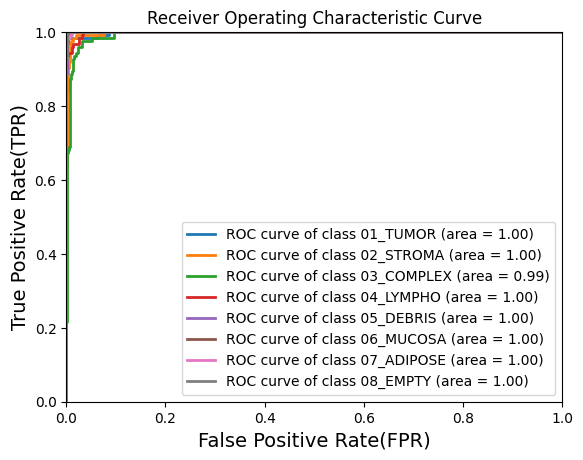

In [32]:
roc_curve_multi(pred_all, label_all.astype('int'), f"AUROC_curve.png", target_names)

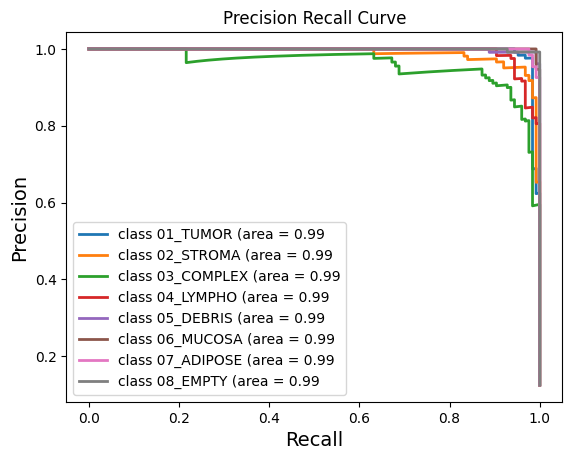

In [33]:
prauc_curve_multi(pred_all, label_all.astype('int'), f"Precision_Recall_curve.png", target_names)

📥 CRC-VAL-HE-7K 다운로드 중...
--2026-08-18 06:54:19--  https://zenodo.org/records/1214456/files/CRC-VAL-HE-7K.zip?download=1
Resolving zenodo.org (zenodo.org)... 188.184.98.114, 137.138.153.219, 188.185.43.153, ...
Connecting to zenodo.org (zenodo.org)|188.184.98.114|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 800276929 (763M) [application/octet-stream]
Saving to: ‘CRC-VAL-HE-7K.zip’

CRC-VAL-HE-7K.zip   100%[===================>] 763.20M  2.48MB/s    in 5m 34s  

2026-08-18 06:59:55 (2.28 MB/s) - ‘CRC-VAL-HE-7K.zip’ saved [800276929/800276929]

📦 압축 해제 중...
✅ 데이터 준비 완료!

📊 테스트 클래스 목록 (9개): ['ADI', 'BACK', 'DEB', 'LYM', 'MUC', 'MUS', 'NORM', 'STR', 'TUM']
이미지 총 개수: 7180장

🚀 외부 데이터셋 검증 시작... (잠시만 기다려주세요)
✅ 검증 완료!

--------------------------------------------------
             [ Classification Report ]
--------------------------------------------------
              precision    recall  f1-score   support

         ADI       0.01      0.00      0.00      1338
 

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/IPython/c

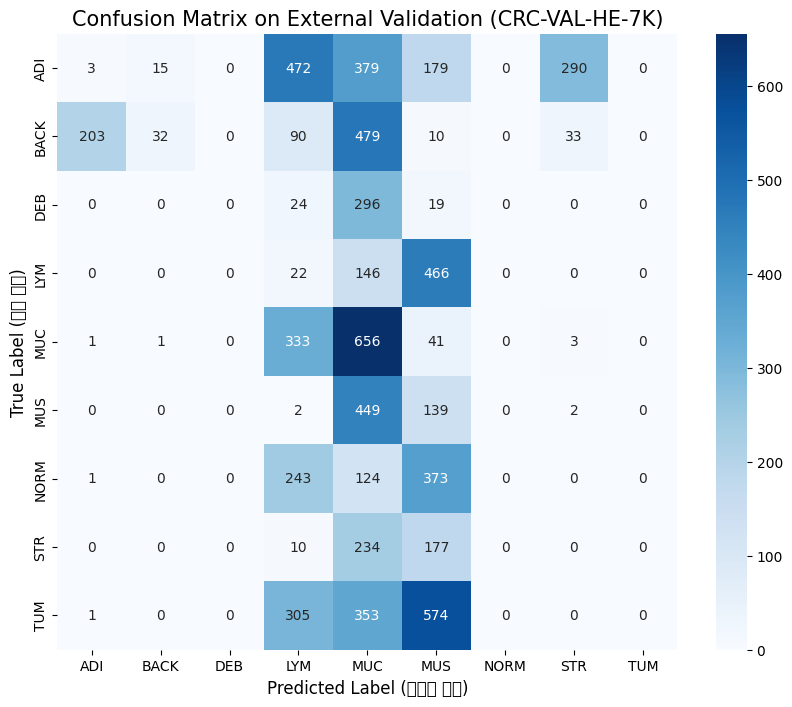

In [25]:
import os
import numpy as np
import torch
from torchvision import datasets, transforms
import torch.utils.data as data
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# =========================================================
# 1. 외부 검증 데이터셋 (CRC-VAL-HE-7K) 다운로드 및 압축 해제
# =========================================================
print("📥 CRC-VAL-HE-7K 다운로드 중...")
!wget -O CRC-VAL-HE-7K.zip --no-check-certificate https://zenodo.org/records/1214456/files/CRC-VAL-HE-7K.zip?download=1

print("📦 압축 해제 중...")
!unzip -q -o CRC-VAL-HE-7K.zip
print("✅ 데이터 준비 완료!\n")


# =========================================================
# 2. 데이터로더 셋팅
# =========================================================
val_dataset_folder = "CRC-VAL-HE-7K"

# 학습 단계에서 사용한 검증용 전처리(Transform)와 동일하게 적용합니다.
# (ResNet50 기준 224x224 리사이즈 및 ImageNet 정규화)
test_transforms = transforms.Compose([
    transforms.Resize(size=224),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# 폴더 구조를 그대로 라벨로 읽어오는 ImageFolder 사용
test_dataset = datasets.ImageFolder(root=val_dataset_folder, transform=test_transforms)
test_loader = data.DataLoader(test_dataset, batch_size=64, shuffle=False, num_workers=1)

print(f"📊 테스트 클래스 목록 ({len(test_dataset.classes)}개):", test_dataset.classes)
print(f"이미지 총 개수: {len(test_dataset)}장\n")


# =========================================================
# 3. 모델 외부 검증 진행
# =========================================================
pred_all = []
label_all = []

model.eval() # 모델을 평가 모드로 전환 (Dropout, BatchNorm 고정)
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

print("🚀 외부 데이터셋 검증 시작... (잠시만 기다려주세요)")
with torch.no_grad(): # 검증 시에는 기울기(Gradient) 계산을 하지 않아 메모리 절약
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        outputs = model(inputs)
        # 확률값이 가장 높은 인덱스를 예측값으로 선택
        preds = torch.argmax(outputs, dim=1)

        pred_all.extend(preds.cpu().numpy())
        label_all.extend(labels.cpu().numpy())

print("✅ 검증 완료!\n")


# =========================================================
# 4. 결과 출력 및 시각화
# =========================================================
# 4-1. 평가지표 출력 (Precision, Recall, F1-Score)
print("-" * 50)
print("             [ Classification Report ]")
print("-" * 50)
print(classification_report(label_all, pred_all, target_names=test_dataset.classes))

# 4-2. 혼동 행렬(Confusion Matrix) 시각화
conf_mat = confusion_matrix(label_all, pred_all)

plt.figure(figsize=(10, 8))
sns.heatmap(conf_mat, annot=True, fmt='d', cmap='Blues',
            xticklabels=test_dataset.classes,
            yticklabels=test_dataset.classes)
plt.title('Confusion Matrix on External Validation (CRC-VAL-HE-7K)', fontsize=15)
plt.ylabel('True Label (실제 정답)', fontsize=12)
plt.xlabel('Predicted Label (모델의 예측)', fontsize=12)
plt.show()

In [ ]:
import os
import shutil

# 구글 드라이브 내 저장 경로 (원하시는 경로로 수정 가능)
drive_zip_path = '/content/drive/MyDrive/NCT-CRC-HE-100K.zip'
local_zip_path = '/content/NCT-CRC-HE-100K.zip'
extract_path = '/content/NCT-CRC-HE-100K'

print("--- 📦 데이터 준비 단계 ---")

# 1. 드라이브에 zip 파일이 없다면 최초 1회만 다운로드
if not os.path.exists(drive_zip_path):
    print("📥 구글 드라이브에 파일이 없습니다. 최초 1회 다운로드를 시작합니다 (약 2GB)...")
    !wget -O "{drive_zip_path}" --no-check-certificate https://zenodo.org/records/1214456/files/NCT-CRC-HE-100K.zip?download=1
else:
    print("✅ 구글 드라이브에 데이터(.zip)가 이미 존재합니다. (다운로드 생략)")

# 2. 로컬에 압축 폴더가 없다면 드라이브에서 복사 후 압축 해제 (학습 속도 최적화)
if not os.path.exists(extract_path):
    print("🚀 코랩 로컬 스토리지로 파일 복사 중...")
    shutil.copy(drive_zip_path, local_zip_path)

    print("📦 로컬에서 압축 해제 중...")
    !unzip -q -o "{local_zip_path}" -d /content/
    print("✅ 로컬 데이터 세팅 완료!\n")
else:
    print("✅ 이미 로컬에 압축이 해제되어 있습니다.\n")

In [26]:
import os
import torch
import torch.nn as nn
from torchvision import datasets, transforms, models
import torch.utils.data as data
import torch.optim as optim
from torch.optim import lr_scheduler



# =========================================================
# 2. 데이터셋 및 데이터로더 설정 (학습: 100K / 검증: 7K)
# =========================================================
train_dataset_folder = "NCT-CRC-HE-100K"
val_dataset_folder = "CRC-VAL-HE-7K"  # 앞서 다운로드한 외부 검증 데이터

image_transforms = {
    'train': transforms.Compose([
        transforms.Resize(size=224),
        transforms.RandomRotation(90, expand=False),
        transforms.RandomRotation(180, expand=False),
        transforms.RandomRotation(270, expand=False),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'valid': transforms.Compose([
        transforms.Resize(size=224),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ])
}

# 10만장 전체를 Train으로, 7천장 전체를 Valid로 바로 연결합니다.
dataset = {
    'train': datasets.ImageFolder(root=train_dataset_folder, transform=image_transforms['train']),
    'valid': datasets.ImageFolder(root=val_dataset_folder, transform=image_transforms['valid'])
}

dataset_sizes = {
    'train': len(dataset['train']),
    'valid': len(dataset['valid'])
}

# 메모리 최적화를 위해 num_workers 설정
dataloaders = {
    'train': data.DataLoader(dataset['train'], batch_size=64, shuffle=True, num_workers=2, pin_memory=True),
    'valid': data.DataLoader(dataset['valid'], batch_size=64, shuffle=False, num_workers=2, pin_memory=True)
}

print(f"📊 학습 데이터(Train): {dataset_sizes['train']}장")
print(f"📊 검증 데이터(Valid): {dataset_sizes['valid']}장")
print(f"📌 클래스 목록 (9개): {dataset['train'].classes}\n")


# =========================================================
# 3. 9개 클래스를 분류하기 위한 ResNet50 모델 재설계
# =========================================================
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model = models.resnet50(pretrained=True)

# 🌟 핵심 수정: 기존 출력 노드 8개 -> 9개로 변경
model.fc = nn.Sequential(
    nn.Linear(2048, 128),
    nn.ReLU(inplace=True),
    nn.Linear(128, 9)
)
model = model.to(device)


# =========================================================
# 4. 학습 셋팅 (손실함수, 옵티마이저, 스케줄러)
# =========================================================
loss_fn = nn.CrossEntropyLoss()
opt = optim.SGD(model.parameters(), lr=0.005, momentum=0.9)
scheduler = lr_scheduler.StepLR(opt, step_size=7, gamma=0.1)

print("🚀 10만 장 데이터 기반 모델 셋팅 완료! 이제 기존의 `train_model` 함수를 실행하시면 됩니다.")

📥 NCT-CRC-HE-100K 다운로드 중 (크기가 약 2GB라 시간이 조금 걸립니다)...
--2026-08-18 07:20:49--  https://zenodo.org/records/1214456/files/NCT-CRC-HE-100K.zip?download=1
Resolving zenodo.org (zenodo.org)... 137.138.153.219, 137.138.52.235, 188.184.98.114, ...
Connecting to zenodo.org (zenodo.org)|137.138.153.219|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 11690284003 (11G) [application/octet-stream]
Saving to: ‘NCT-CRC-HE-100K.zip’

NCT-CRC-HE-100K.zip   0%[                    ]  97.28M   635KB/s    eta 4h 5m  ^C
📦 압축 해제 중...
[NCT-CRC-HE-100K.zip]
  End-of-central-directory signature not found.  Either this file is not
  a zipfile, or it constitutes one disk of a multi-part archive.  In the
  latter case the central directory and zipfile comment will be found on
  the last disk(s) of this archive.
unzip:  cannot find zipfile directory in one of NCT-CRC-HE-100K.zip or
        NCT-CRC-HE-100K.zip.zip, and cannot find NCT-CRC-HE-100K.zip.ZIP, period.
✅ 데이터 준비 완료!



FileNotFoundError: [Errno 2] No such file or directory: 'NCT-CRC-HE-100K'

In [ ]:
# 빠른 건전성 검사(Sanity Check)를 위해 에포크를 1로 대폭 줄입니다.
test_epoch = 1

print("\n--- 🚀 [Test Run] 1 Epoch 빠른 학습 및 검증 시작 ---")
# 위에서 9개 클래스용으로 새롭게 정의한 model, loss_fn, opt, scheduler를 그대로 넣습니다.
model = train_model(model, loss_fn, opt, scheduler, num_epochs=test_epoch)
print("\n✅ 에러 없이 1 에포크 학습/검증이 무사히 완료되었습니다!")

In [ ]:
# Model training routine
print("\nTraining:-\n")

model = train_model(model, loss_fn, opt, scheduler, num_epochs=train_epoch)